# Домашнее задание 4. Деревья и ансамбли
## Математические методы анализа данных

В этом ДЗ вы участвуете в соревновании **«Лес учится видеть»**: строите модель на основе деревьев решений и предсказываете класс каждого пикселя изображения.

**Дата публикации:** 9 ноября 2026.  
**Дедлайн:** 21 ноября 2026, 23:00 (МСК).  
**Максимальный балл:** 10.

Для сдачи в LMS заполните **карточку участника** в конце этого ноутбука и коротко поясните, за счёт чего ваш скор выше, чем у базового решения. Исполняемое решение загружается на платформу соревнования. Проверяющий находит вас по имени в лидерборде и рассчитывает оценку по результату на **private**.

# Лес учится видеть · базовое решение

Скачайте [архив соревнования](https://vsos.colloq.ru/api/k/competitions/trees-textures/files.zip). Положите тетрадь рядом с распакованной папкой `data/` и запустите все ячейки по порядку. На платформе эта папка уже есть. Последняя ячейка создаст `submission.csv`.

Стартовая модель использует окно 9×9, 10 деревьев и 16 384 обучающих пикселя. Свой признак можно добавить в `my_features` и сразу увидеть изменение на карте ошибок.


In [ ]:
from pathlib import Path
import csv
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy.ndimage import uniform_filter, maximum_filter, minimum_filter
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import balanced_accuracy_score
from matplotlib.patches import Patch

DATA = Path('data')
WINDOW = 9
TREES = 10
PALETTE = np.array([[49, 104, 174], [221, 151, 39], [52, 144, 104], [157, 91, 164]], dtype=np.uint8)
NAMES = ['Горизонтальные штрихи', 'Вертикальные штрихи', 'Пятна', 'Диагональные полосы']

def read_public(name):
    path = DATA / name
    if not path.is_file():
        raise FileNotFoundError(f'Не найден {path}. Положите тетрадь рядом с распакованной папкой data/.')
    with Image.open(path) as image:
        return np.asarray(image).copy()

def features(gray, window, extra):
    # На исходной картинке в пикселе одно число — яркость.
    # Каждый признак добавляет этому же пикселю ещё одно число.
    # Лес получает их вместе: яркость, контраст, разность с соседом справа и то, что добавлено в my_features.
    custom = extra(gray.astype(np.float32) / 255, window)
    fields = base_features(gray, window) + list(custom)
    for field in fields:
        if np.shape(field) != gray.shape or not np.isfinite(field).all():
            raise ValueError('Каждый признак должен быть конечным массивом формы gray.shape')
    return np.stack(fields, axis=-1).astype(np.float32)

def error_panel(image, truth, pred):
    # Красным отмечен пиксель, у которого ответ леса отличается от класса в маске.
    panel = np.repeat((image * 0.4 + 30).astype(np.uint8)[:, :, None], 3, axis=2)
    panel[truth != pred] = [218, 50, 55]
    return panel

def boundary_mask(mask, k=7):
    # Пиксель на стыке: в квадрате 7×7 вокруг него лежат разные классы из маски.
    # Окно вокруг такого пикселя захватывает две текстуры сразу.
    return maximum_filter(mask, size=k, mode='nearest') != minimum_filter(mask, size=k, mode='nearest')

def error_rates(truth, pred):
    err = pred != truth
    border = boundary_mask(truth)
    return float(err[border].mean()), float(err[~border].mean())

def recall_per_class(truth, pred):
    recalls = []
    flat_t, flat_p = truth.ravel(), pred.ravel()
    for label in range(4):
        chosen = flat_t == label
        recalls.append(float((flat_p[chosen] == label).mean()) if chosen.any() else 0.0)
    return recalls

cache = {}

def get_model(window, trees):
    key = (int(window), int(trees), my_features)
    if key not in cache:
        cache[key] = fit_forest(key[0], key[1], my_features)
    return cache[key]

def show(ax, image, title):
    ax.imshow(image, cmap='gray', vmin=0, vmax=255, interpolation='nearest')
    ax.set_title(title)
    ax.axis('off')


## 1. Задание и ограничения

- [Условие и данные соревнования](https://vsos.colloq.ru/k/trees-textures)
- [Лидерборд соревнования](https://vsos.colloq.ru/k/trees-textures/leaderboard)

Нужно отнести каждый пиксель к одному из четырёх классов: **0, 1, 2 или 3**. Метрика — **Balanced Accuracy**, средняя полнота по четырём классам. Чем больше значение, тем лучше.

В данных есть два обучающих изображения и их маски: `train_0.png`, `train_1.png`, `mask_0.png`, `mask_1.png`. Для собственной проверки используйте `val.png` и `val_mask.png`. При проверке на платформе `data/test.png` заменяется скрытым изображением, размеры которого могут отличаться от открытого примера.

**Основные ограничения соревнования:**

- Разрешены деревья решений, случайный лес и бустинг на деревьях.
- В итоговой модели — **суммарно не более 100 деревьев**; для обучения — **не более 20 000 уникальных пикселей**. Считайте фактические деревья: у многоклассового бустинга одна итерация может создавать несколько деревьев.
- Нейросети и готовые сегментаторы запрещены.
- Ноутбук запускается с нуля, сверху вниз, **без интернета**: до **10 минут**, **4 ГБ памяти**, **2 ядра**. На платформе доступно до **5 посылок в день**.
- Результат работы — `submission.csv` с колонками `id,label`. Индексы начинаются с 0; пиксели идут слева направо, сверху вниз. Число строк определяйте по текущему `data/test.png`.

Можно экспериментировать с признаками, обработкой изображений и настройками разрешённых моделей. Полное условие и окружение проверки приведены на странице соревнования.

## 2. Признаки пикселя

Базовые признаки — яркость, стандартное отклонение в окне и средняя абсолютная разность яркостей соседей по горизонтали. В `my_features` поступает изображение с яркостями от 0 до 1. Верните по одному двумерному массиву той же формы на каждый новый признак.


In [ ]:
def mean_window(a, window):
    # Для каждого пикселя считаем среднее по квадрату вокруг него.
    # У края картинки квадрат вылезает наружу. Недостающие пиксели берём зеркальным отражением.
    return uniform_filter(a.astype(np.float32), size=window, mode='reflect')

def base_features(gray, window):
    # В файле яркость — целое от 0 до 255. Нормализуем к диапазону 0 - 1
    image = gray.astype(np.float32) / 255
    # Насколько сильно яркость скачет внутри окна - это контраст
    # Горизонтальный и вертикальный штрих одинаковой резкости дают похожее число
    local_mean = mean_window(image, window)
    local_sd = np.sqrt(np.maximum(mean_window(image * image, window) - local_mean**2, 0))
    # Насколько этот пиксель отличается от соседа справа.
    # Вычитание даёт минус, если сосед темнее. Модуль убирает знак, остаётся величина от 0 до 1.
    # Вертикальный штрих дает большое отличие слева направо
    # Горизонтальный штрих идёт вдоль строки, сосед справа похож, отличие маленькое.
    dx = np.abs(np.diff(image, axis=1, append=image[:, -1:]))
    return [image, local_sd, mean_window(dx, window)]


In [2]:
def my_features(gray, window):
    # gray — яркость от 0 до 1. Новый признак — картинка той же высоты и ширины.
    # Добавьте свои признаки в список.
    return []


## 3. Открытая валидация и её разметка

На входе — чёрно-белое изображение. Для каждого пикселя нужно предсказать один из четырёх классов текстуры. Ниже — открытая валидация и её разметка.


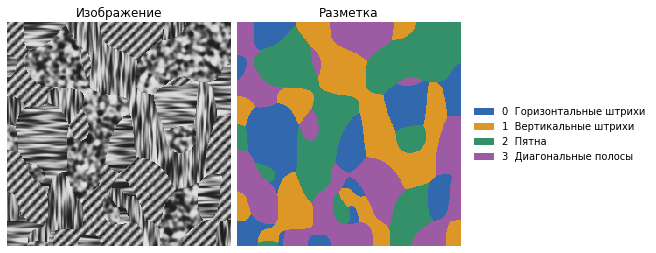

In [3]:
train = read_public('val.png')
mask = read_public('val_mask.png')

fig, axes = plt.subplots(1, 2, figsize=(9, 4.2), constrained_layout=True)
show(axes[0], train, 'Изображение')
axes[1].imshow(PALETTE[mask], interpolation='nearest')
axes[1].set_title('Разметка')
axes[1].axis('off')
axes[1].legend(
    handles=[Patch(facecolor=PALETTE[i] / 255, label=f'{i}  {NAMES[i]}') for i in range(4)],
    loc='center left', bbox_to_anchor=(1.02, 0.5), frameon=False,
)
plt.show()


## 4. Два пикселя одной яркости

Красная рамка отмечает центр каждого фрагмента. В обоих случаях яркость равна 128. Какой признак позволит дереву различить направления штрихов?


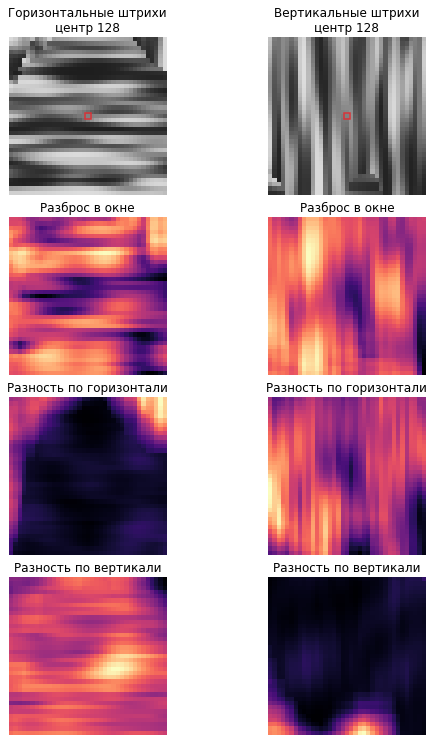

In [4]:
def pick_patch(label, radius=18):
    best = None
    best_score = -1e9
    for name_i in range(2):
        image = read_public(f'train_{name_i}.png')
        mask = read_public(f'mask_{name_i}.png')
        height, width = image.shape
        ys, xs = np.where((image == 128) & (mask == label))
        for y, x in zip(ys.tolist(), xs.tolist()):
            if not (radius <= y < height - radius and radius <= x < width - radius):
                continue
            view = (slice(y - radius, y + radius + 1), slice(x - radius, x + radius + 1))
            if (mask[view] == label).mean() < 0.7:
                continue
            crop = image[view].astype(np.float32)
            dx = np.abs(np.diff(crop, axis=1)).mean()
            dy = np.abs(np.diff(crop, axis=0)).mean()
            score = (dy - dx) if label == 0 else (dx - dy)
            if score > best_score:
                best_score = float(score)
                best = (name_i, int(y), int(x))
    if best is None:
        raise RuntimeError(f'Не нашёлся фрагмент класса {label} с яркостью 128 в центре')
    return best

def crop_at(array, y, x, radius):
    return array[y - radius:y + radius + 1, x - radius:x + radius + 1]

radius = 18
choice = [pick_patch(0, radius), pick_patch(1, radius)]
fig, axes = plt.subplots(4, 2, figsize=(7.2, 10.2), constrained_layout=True)
row_names = ['Фрагмент', 'Разброс в окне', 'Разность по горизонтали', 'Разность по вертикали']
for column, (name_i, y, x) in enumerate(choice):
    image = read_public(f'train_{name_i}.png')
    maps = features(image, WINDOW, lambda gray, window: [])
    # То же сравнение, но с соседом снизу. Эта картинка только на рисунке, лес её не получает.
    vertical = mean_window(
        np.abs(np.diff(image.astype(np.float32) / 255, axis=0, append=image[-1:, :])),
        WINDOW,
    )
    panels = [image, maps[:, :, 1], maps[:, :, 2], vertical]
    for row, panel in enumerate(panels):
        ax = axes[row, column]
        view = crop_at(panel, y, x, radius)
        if row == 0:
            show(ax, view, f'{NAMES[column]}\nцентр {int(image[y, x])}')
            ax.plot(radius, radius, 's', ms=6, mfc='none', mec='#da3237', mew=1.5)
        else:
            ax.imshow(view, cmap='magma', interpolation='nearest')
            ax.set_title(row_names[row])
            ax.axis('off')
plt.show()


## 5. Проверьте свой признак

В `my_features(gray, window)` добавьте один признак. Лес уже видит яркость, стандартное отклонение и среднюю разность по горизонтали. Какую информацию ему стоит добавить? Верните массив размера изображения в списке.

Запустите ячейки ниже и сравните карты при прежних настройках.


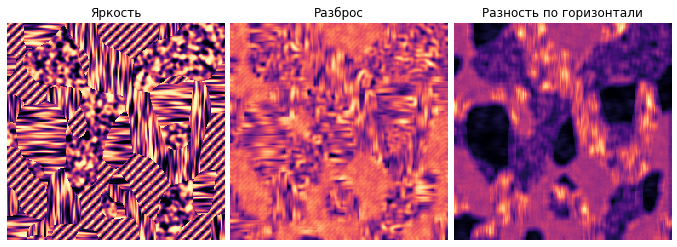

In [5]:
view = read_public('val.png')
maps = features(view, WINDOW, my_features)
titles = ['Яркость', 'Разброс', 'Разность по горизонтали']
titles += [f'Свой признак {i + 1}' for i in range(maps.shape[-1] - 3)]
fig, axes = plt.subplots(1, maps.shape[-1], figsize=(3.1 * maps.shape[-1], 3.3), constrained_layout=True)
if maps.shape[-1] == 1:
    axes = [axes]
for ax, title, channel in zip(axes, titles, range(maps.shape[-1])):
    ax.imshow(maps[:, :, channel], cmap='magma', interpolation='nearest')
    ax.set_title(title)
    ax.axis('off')
plt.show()


## 6. Обучение

Из каждой обучающей маски выбираем 8 192 пикселя без повторов. Фиксированный seed позволяет сравнивать признаки на одной и той же выборке.


In [ ]:
def sample_ids(images):
    # Из каждой обучающей маски берём 8192 пикселя без повторов.
    # Стартовое число 41 одно и то же, поэтому набор пикселей не меняется от запуска к запуску.
    rng = np.random.default_rng(41)
    return [rng.choice(im.size, min(8192, im.size), replace=False) for im in images]

def fit_forest(window, trees, extra):
    # Окно нечётное, чтобы в центре был ровно один пиксель.
    # У окна 9×9 это центр и по четыре пикселя вверх, вниз, влево и вправо.
    if window < 1 or window % 2 != 1 or not 1 <= trees <= 100:
        raise ValueError('Окно должно быть положительным и нечётным, число деревьев — от 1 до 100')
    images = [read_public(f'train_{i}.png') for i in range(2)]
    ids = sample_ids(images)
    rows, labels = [], []
    for i, (image, idx) in enumerate(zip(images, ids)):
        f = features(image, window, extra)
        # Одна строка таблицы — один пиксель. Столбцов несколько: по одному числу на каждый признак.
        # Правильный ответ для этой строки берём из маски в том же пикселе.
        rows.append(f.reshape(image.size, -1)[idx])
        labels.append(read_public(f'mask_{i}.png').ravel()[idx])
    forest = RandomForestClassifier(n_estimators=trees, min_samples_leaf=3,
                                    max_features=1.0, random_state=41, n_jobs=2)
    forest.fit(np.concatenate(rows), np.concatenate(labels))
    return forest

def predict_image(forest, image, window, extra):
    # Лес смотрит на каждый пиксель отдельно и ставит ему класс.
    # Из этих ответов снова собирается картинка того же размера.
    f = features(image, window, extra)
    return forest.predict(f.reshape(image.size, -1)).reshape(image.shape).astype(np.uint8)


## 7. Размер окна

Оставьте 10 деревьев. Сначала предположите, в каком окне будет меньше ошибок на стыке двух текстур. Затем сравните карты ошибок.

Пиксель относится к границе, если в квадрате 7×7 вокруг него встречаются разные истинные классы.


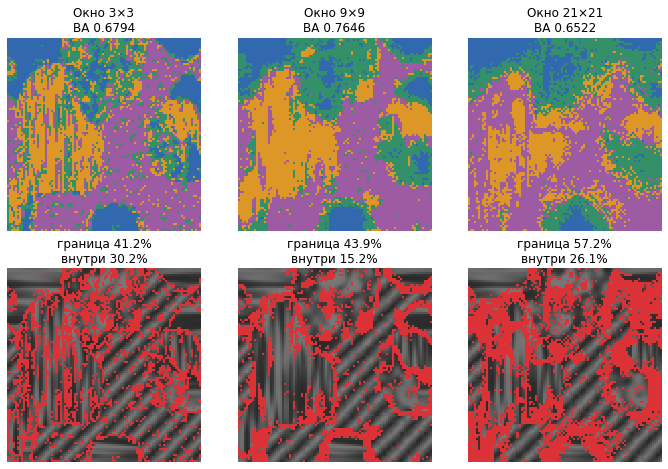

In [6]:

cache.clear()
val = read_public('val.png')
truth = read_public('val_mask.png')
border = boundary_mask(truth)

def interesting_crop(size=96):
    best = (0, 0, -1)
    for y in range(0, truth.shape[0] - size + 1, 8):
        for x in range(0, truth.shape[1] - size + 1, 8):
            patch = truth[y:y + size, x:x + size]
            score = int(border[y:y + size, x:x + size].sum()) + 500 * len(np.unique(patch))
            if score > best[2]:
                best = (y, x, score)
    return best[0], best[1]

crop_y, crop_x = interesting_crop()
crop = (slice(crop_y, crop_y + 96), slice(crop_x, crop_x + 96))
# Размер окна — сколько соседей вокруг пикселя участвует в его описании.
windows = [3, 9, 21]
fig, axes = plt.subplots(2, 3, figsize=(9.6, 6.4), constrained_layout=True)
for column, window in enumerate(windows):
    pred = predict_image(get_model(window, 10), val, window, my_features)
    score = balanced_accuracy_score(truth.ravel(), pred.ravel())
    on_border, inside = error_rates(truth, pred)
    axes[0, column].imshow(PALETTE[pred[crop]], interpolation='nearest')
    axes[0, column].set_title(f'Окно {window}×{window}\nBA {score:.4f}')
    axes[0, column].axis('off')
    axes[1, column].imshow(error_panel(val, truth, pred)[crop], interpolation='nearest')
    axes[1, column].set_title(f'граница {on_border:.1%}\nвнутри {inside:.1%}')
    axes[1, column].axis('off')
plt.show()


## 8. Число деревьев

Сравните 1, 10 и 100 деревьев при окне 9×9. Где увеличение леса ещё помогает?


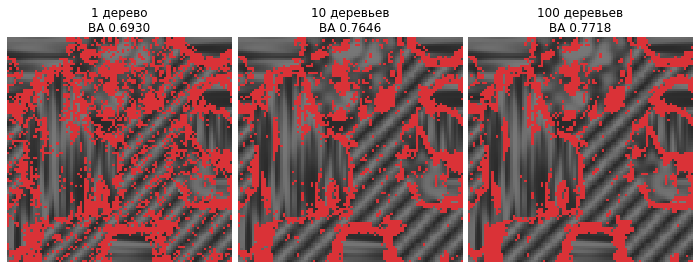

In [7]:

def trees_label(count):
    if count % 10 == 1 and count % 100 != 11:
        word = 'дерево'
    elif count % 10 in (2, 3, 4) and count % 100 not in (12, 13, 14):
        word = 'дерева'
    else:
        word = 'деревьев'
    return f'{count} {word}'

fig, axes = plt.subplots(1, 3, figsize=(9.6, 3.6), constrained_layout=True)
for ax, trees in zip(axes, [1, 10, 100]):
    pred = predict_image(get_model(WINDOW, trees), val, WINDOW, my_features)
    score = balanced_accuracy_score(truth.ravel(), pred.ravel())
    ax.imshow(error_panel(val, truth, pred)[crop], interpolation='nearest')
    ax.set_title(f'{trees_label(trees)}\nBA {score:.4f}')
    ax.axis('off')
plt.show()


## 9. Проверка на открытой валидации

Balanced Accuracy считается по всему `val.png`. На карте ошибок красным отмечены пиксели, у которых предсказание отличается от истинного класса.


Balanced Accuracy на val: 0.7646
Полнота: Горизонтальные штрихи 0.796, Вертикальные штрихи 0.753, Пятна 0.732, Диагональные полосы 0.778


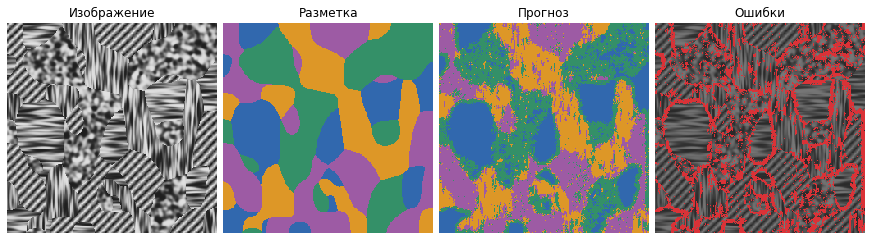

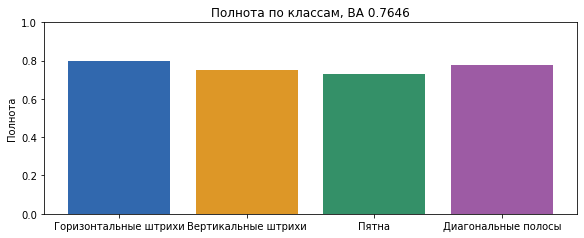

In [8]:
model = get_model(WINDOW, TREES)
pred = predict_image(model, val, WINDOW, my_features)
score = balanced_accuracy_score(truth.ravel(), pred.ravel())
recalls = recall_per_class(truth, pred)
print(f'Balanced Accuracy на val: {score:.4f}')
print('Полнота: ' + ', '.join(f'{name} {value:.3f}' for name, value in zip(NAMES, recalls)))

fig, axes = plt.subplots(1, 4, figsize=(12, 3.2), constrained_layout=True)
for ax, title, panel in zip(
    axes,
    ['Изображение', 'Разметка', 'Прогноз', 'Ошибки'],
    [val, PALETTE[truth], PALETTE[pred], error_panel(val, truth, pred)],
):
    show(ax, panel, title)
plt.show()

fig, ax = plt.subplots(figsize=(8, 3.2), constrained_layout=True)
ax.bar(NAMES, recalls, color=PALETTE / 255)
ax.set_ylim(0, 1)
ax.set_ylabel('Полнота')
ax.set_title(f'Полнота по классам, BA {score:.4f}')
plt.show()


## 10. Как сдать ДЗ

1. Прочитайте условие и скачайте данные со страницы соревнования.
2. Подготовьте решение и загрузите **исполняемый `.ipynb` на платформу соревнования**. Убедитесь, что посылка успешно проверена и у вас появился результат.
3. Заполните карточку в конце этого ноутбука: ФИО, группу и **точное имя участника, как в лидерборде**. Если отображается ник с `@`, укажите его целиком. Не меняйте имя до завершения проверки ДЗ.
4. Под карточкой, в ячейке «Пояснение к решению», коротко опишите, за счёт чего ваш скор выше, чем у базового решения.
5. Переименуйте этот файл в `HW4_Фамилия_Имя.ipynb` и сдайте его **через LMS до дедлайна**.

**В LMS достаточно ноутбука с заполненной карточкой и коротким пояснением к решению.** Дублировать в нём код решения, писать отдельный отчёт или прикладывать скриншот лидерборда не требуется. PDF — версия условия для чтения; сдавать нужно `.ipynb`.

Оценка целиком определяется качеством на **приватной части теста**. За оформление, число экспериментов и текстовые ответы отдельных баллов нет.


## 11. Посылка

Сервер заменяет `data/test.png` скрытым изображением. Размер берём из файла, пиксели обходим построчно. Загрузите исполняемый ноутбук на [страницу посылок](https://vsos.colloq.ru/k/trees-textures/submissions).


In [9]:
model = get_model(WINDOW, TREES)
test = read_public('test.png')
result = predict_image(model, test, WINDOW, my_features)
assert result.shape == test.shape and np.isin(result, [0, 1, 2, 3]).all()
with open('submission.csv', 'w', encoding='utf-8', newline='') as file:
    writer = csv.writer(file)
    writer.writerow(['id', 'label'])
    # Пиксели записываем по строкам: слева направо, потом следующая строка.
    # Число строк равно числу пикселей в test.png. Скрытая картинка на сервере может быть другого размера.
    writer.writerows(enumerate(result.ravel(order='C').tolist()))
print(f'Итоговая модель: {TREES} деревьев из 100, 16384 пикселей из 20000')
print(f'submission.csv: {result.size} строк с прогнозами')


Итоговая модель: 10 деревьев из 100, 16384 пикселей из 20000
submission.csv: 30720 строк с прогнозами


## 12. Оценивание

Обозначим через **s** ваш итоговый **Balanced Accuracy на private**. Проверяющий берёт этот результат из приватного лидерборда после его открытия.

Границы шкалы зафиксированы по публичному лидерборду **4 ноября 2026 года**:

| Порог | Значение | Откуда взят |
|---|---:|---|
| Нижний: 0 баллов | **0,9395** | Второе место на public |
| Верхний: 10 баллов | **0,9757** | Первое место на public |

Эти числа **не меняются** при появлении новых участников или результатов. Пороги взяты с public, но в формулу подставляется именно ваш результат на private, а не место в таблице.


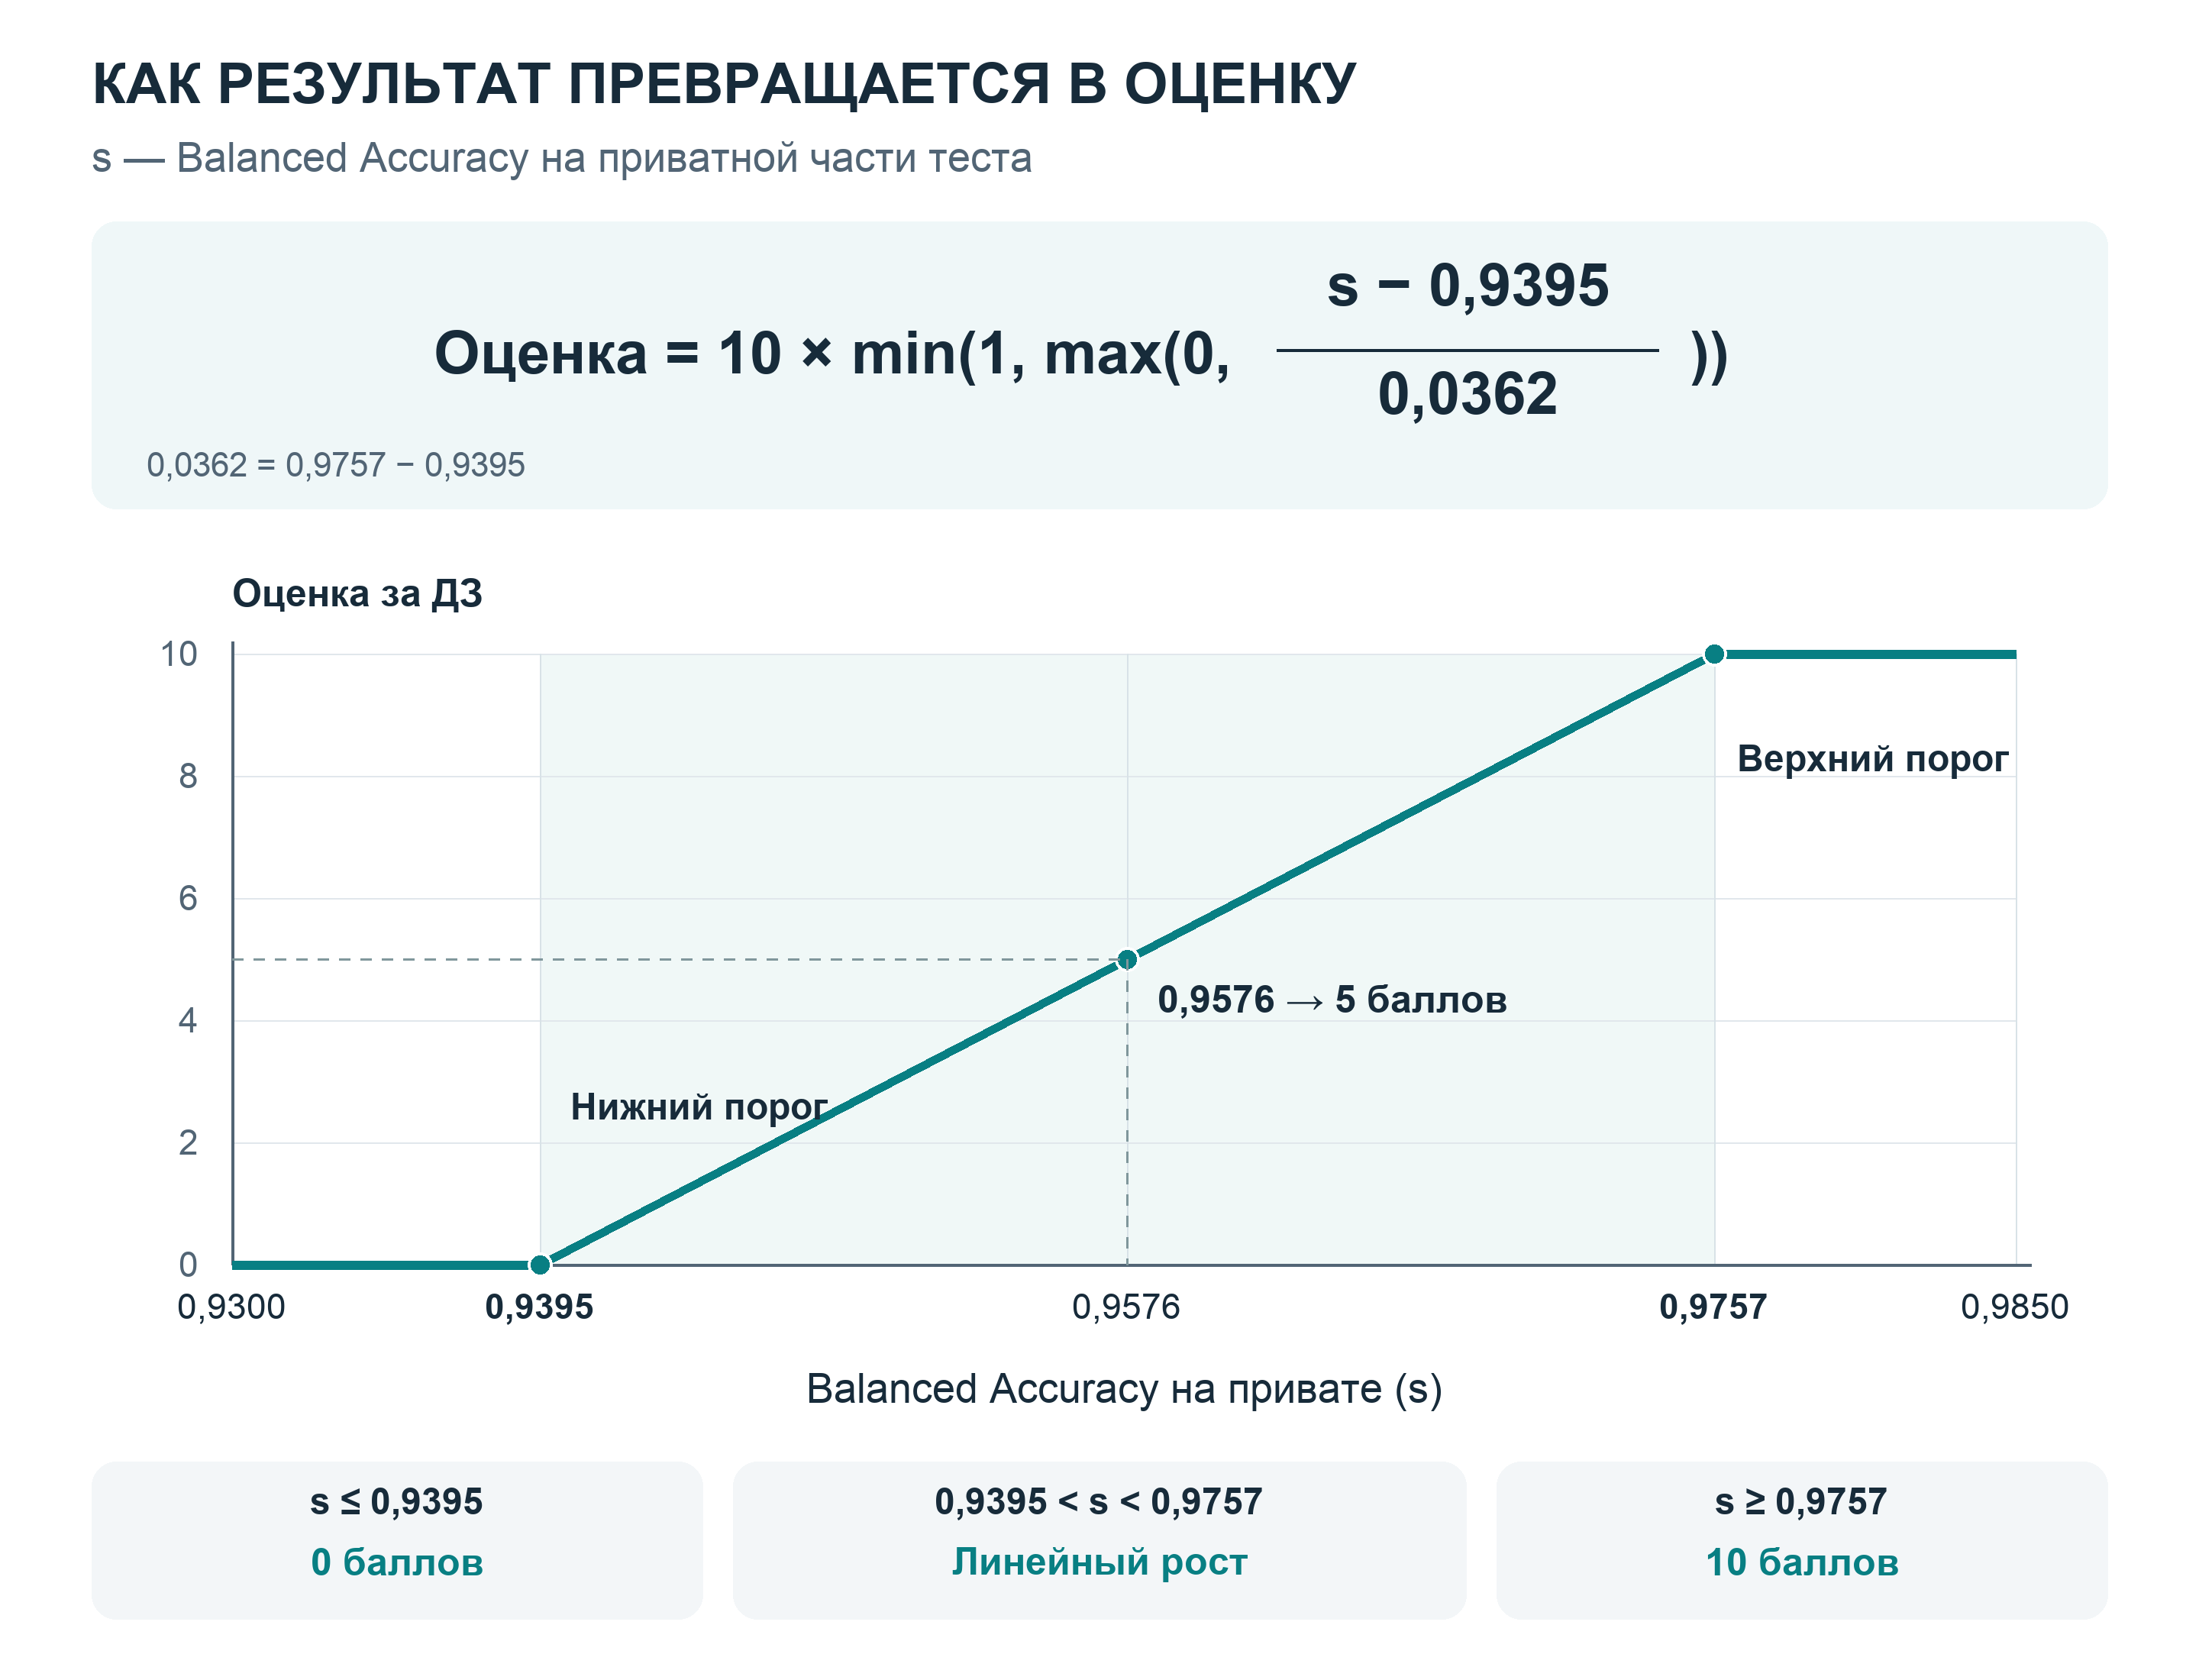

Например, при **s = 0,9576** оценка равна **5 баллам**. При **s = 0,9500** — примерно **2,90 балла**. Оценка ограничена диапазоном от 0 до 10; результат записывается с точностью до двух знаков после запятой.

Публичный результат нужен для обратной связи во время соревнования. Он не заменяет результат на private при выставлении оценки.

**Что нужно от вас для оценки:**

- В ноутбуке, который вы сдаёте в LMS, коротко поясните, за счёт чего ваш скор выше, чем у базового решения из этого ноутбука: что вы добавили или изменили (признаки, обработку изображения, модель и её настройки) и что из этого дало заметный прирост. Достаточно нескольких предложений в ячейке «Пояснение к решению» в конце ноутбука.

## 13. Карточка участника — заполните перед сдачей

Замените текст в квадратных скобках своими данными. Имя в лидерборде должно позволять проверяющему однозначно найти ваш результат.

| Поле | Ваши данные |
|---|---|
| Фамилия и имя | [Впишите фамилию и имя] |
| Учебная группа | [Впишите группу] |
| Точное имя / ник в лидерборде | [Скопируйте имя из лидерборда] |

**Перед сдачей проверьте:**

- На платформе есть хотя бы одна успешно проверенная посылка с результатом.
- ФИО, группа и имя в лидерборде заполнены; имя указано без ошибок.
- Пояснение к решению в ячейке ниже заполнено.
- В LMS загружается файл `HW4_Фамилия_Имя.ipynb` до дедлайна.

**Для проверяющего:** найдите участника по указанному имени, возьмите его итоговый Balanced Accuracy на private и примените формулу из раздела 12. Значение метрики, вписанное студентом, или скриншот public для оценки не используются.


### Пояснение к решению

Замените текст в квадратных скобках. Хватит нескольких предложений: что вы добавили или изменили по сравнению с базовым решением и что из этого дало прирост скора.

[Опишите, за счёт чего ваш скор выше, чем у базового решения]